# Hierarchical priors and multiplicity in age × diet interactions

**Question:** When the age × diet interaction effects from many small 2×2 ANOVAs share a hierarchical prior, which phenotypes have credible intervals that exclude zero, and how sensitive is that set to the specification of the shared effect distribution?

Each phenotype is measured in a 2×2 design: age (young, old) × diet (control, intermittent fasting). The parameter of interest is the interaction, the difference between the diet effect in old mice and in young mice. A nonzero interaction means the diet changes how the phenotype differs with age.

This notebook sets up the data only. Model specification follows separately.


In [1]:
import gzip
import io
import json

import numpy as np
import numpyro

numpyro.set_host_device_count(
    4
)  # must run before JAX initializes, to sample chains in parallel

import arviz as az
import jax
import jax.numpy as jnp
import numpy as np
import numpyro.distributions as dist
import pandas as pd
import statsmodels.api as sm
from numpyro.infer import MCMC, NUTS
from sklearn.preprocessing import LabelEncoder
from statsmodels.stats.multitest import multipletests

## Data

The data come from [Xie et al. (2022)](https://www.nature.com/articles/s41467-022-34515-y), as prepared in `../mouse_data.json.gz`. The file holds one small table per phenotype, grouped by experiment. We use the `Figure5_phenotypes` group: 157 phenotypes from the intermittent fasting experiment, in which mice were fed every other day (`diet` = `restricted`) or ad libitum (`diet` = `control`). The group names come from the data release and do not match the figure numbers of the published paper, where this experiment is Fig. 8. The young cohort was about 3 months old at the start and the old cohort about 20 months, and phenotyping took about 2 months.

The authors call the interaction a "rate effect" (the diet changes how much the phenotype changes with age), as opposed to a "baseline" effect, which shifts the phenotype equally at both ages. They estimate that about 11% of age-sensitive phenotypes show a diet effect consistent with a rate effect.

Each mouse went through a phenotyping pipeline and contributes to many tables, but the release has no mouse identifiers, so the tables for different phenotypes cannot be linked at the mouse level.


In [2]:
with gzip.open("../mouse_data.json.gz", "rt") as f:
    md = json.load(f)["Figure5_phenotypes"]

len(md)

157

The function below reads one phenotype table and returns it in a common long format. The phenotype value is standardized within each phenotype so that all effects are in units of that phenotype's standard deviation, which makes them comparable across phenotypes. As in the course notebook, the standard deviation is the overall SD across all four cells.

Age and diet are coded as indicators:

- `age` = 1 for old, 0 for young
- `trt` = 1 for intermittent fasting, 0 for control

In the model `y ~ age * trt`, the intercept is the mean for young control mice, the `trt` coefficient is the fasting effect in young mice, the `age` coefficient is the age difference in control mice, and the `age:trt` coefficient is (fasting − control in old mice) − (fasting − control in young mice). A positive interaction means fasting raises the phenotype more (or lowers it less) in old mice than in young mice. **The sign is the reverse of the course notebook's interaction**, which was young minus old. The interaction coefficient does not depend on the choice of coding, but the main effects do.


In [3]:
def load_phenotype(pheno):
    da = pd.read_csv(io.StringIO(md[pheno]))
    da = da.rename(columns={da.columns[-1]: "y"})
    da["y"] = pd.to_numeric(da["y"], errors="coerce")
    da = da.dropna(subset=["y"])
    return pd.DataFrame({
        "phenotype": pheno,
        "y_raw": da["y"].to_numpy(),
        "y": ((da["y"] - da["y"].mean()) / da["y"].std()).to_numpy(),
        "age": np.where(da["age"] == "old", 1, 0),
        "trt": np.where(da["diet"] == "restricted", 1, 0),
    })


df = pd.concat([load_phenotype(p) for p in md], ignore_index=True)
df.head()

,phenotype,y_raw,y,age,trt
0,Heart_rate_Echo,694.98,0.909840,0,0
1,Heart_rate_Echo,670.84,0.728255,0,0
2,Heart_rate_Echo,435.20,-1.044275,0,0
3,Heart_rate_Echo,655.59,0.613541,0,0
4,Heart_rate_Echo,278.05,-2.226388,0,0


Every phenotype table has all four cells, with at least two mice per cell and nonzero variance, so none are dropped. Cells range from 6 to 23 mice. The median cell sizes are:


In [4]:
cells = df.groupby(["phenotype", "age", "trt"]).size()
cells.groupby(["age", "trt"]).median().unstack("trt")

trt,0,1
age,,
0,16.0,16.0
1,20.0,22.0


Sample sizes differ between phenotypes. Most were measured on 64 to 78 mice, but some on a subset of about 30 to 40, so the precision of the interaction estimates varies across phenotypes.


In [5]:
n_per = df.groupby("phenotype").size()
n_per.describe()[["min", "25%", "50%", "75%", "max"]]

min    28.0
25%    64.0
50%    74.0
75%    76.0
max    78.0
dtype: float64

## Arrays for the model

The unit of analysis is a phenotype, with one 2×2 ANOVA per phenotype. The `phenos` table has one row per phenotype, and `data` holds flat observation-level arrays with an integer index linking each observation to its phenotype.


In [6]:
enc = LabelEncoder()
df["idx"] = enc.fit_transform(df["phenotype"])
phenos = pd.DataFrame({"phenotype": enc.classes_, "n": np.bincount(df["idx"])})
phenos["idx"] = np.arange(len(phenos))

data = {
    "y": df["y"].to_numpy(),
    "age": df["age"].to_numpy(),
    "trt": df["trt"].to_numpy(),
    "pheno": df["idx"].to_numpy(),
    "n_pheno": len(phenos),
}
{k: (v.shape if isinstance(v, np.ndarray) else v) for k, v in data.items()}

{'y': (10564,),
 'age': (10564,),
 'trt': (10564,),
 'pheno': (10564,),
 'n_pheno': 157}

## Frequentist reference

For comparison with the Bayesian results, the next cell fits the 2×2 interaction model separately to each phenotype by OLS and applies the usual multiplicity adjustments. These are the per-phenotype estimates any hierarchical model will shrink.


In [7]:
def ols_interaction(d):
    X = np.column_stack([np.ones(len(d)), d["age"], d["trt"], d["age"] * d["trt"]])
    r = sm.OLS(d["y"].to_numpy(), X).fit()
    return pd.Series({
        "est": r.params[3],
        "se": r.bse[3],
        "t": r.tvalues[3],
        "p": r.pvalues[3],
        "df_resid": r.df_resid,
    })


freq = phenos.join(
    df.groupby("idx").apply(ols_interaction, include_groups=False), on="idx"
)
freq["unadjusted"] = freq["p"] < 0.05
freq["bonferroni"] = multipletests(freq["p"], 0.05, "bonferroni")[0]
freq["bh05"] = multipletests(freq["p"], 0.05, "fdr_bh")[0]
freq["bh10"] = multipletests(freq["p"], 0.10, "fdr_bh")[0]

freq[["unadjusted", "bonferroni", "bh05", "bh10"]].sum()

unadjusted    29
bonferroni     1
bh05           4
bh10          15
dtype: int64

The interaction estimates with the smallest p-values:


In [8]:
freq.sort_values("p")[
    ["phenotype", "n", "est", "se", "p", "bonferroni", "bh05", "bh10"]
].head(15)

,phenotype,n,est,se,p,bonferroni,bh05,bh10
137,conc_Insulin,75,-1.587432,0.411704,0.000251,True,True,True
146,eu_transf_arousal,78,-1.193209,0.337336,0.000702,False,True,True
25,Fe,74,-1.132072,0.319366,0.000705,False,True,True
111,QT,41,1.708360,0.482563,0.001099,False,True,True
62,Ly6CmedCD11c,74,1.392536,0.434229,0.002024,False,False,True
120,ST,41,1.695844,0.522172,0.002476,False,False,True
117,RR,41,1.376089,0.442426,0.003589,False,False,True
69,MLy6C,74,-1.264257,0.421612,0.003753,False,False,True
113,QTc,41,1.609885,0.530035,0.004359,False,False,True
35,Glycerol_fasting,77,-1.278750,0.436045,0.004488,False,False,True


## Hierarchical model

Each phenotype $i$ has its own 2×2 regression with normal residuals,

$$y_{ij} = \beta_{0i} + \beta_{1i}\,\text{age}_{ij} + \beta_{2i}\,\text{trt}_{ij} + \beta_{3i}\,\text{age}_{ij}\text{trt}_{ij} + \varepsilon_{ij}, \qquad \varepsilon_{ij} \sim N(0, \sigma_i^2),$$

and each of the four coefficient types is drawn from its own normal population distribution, shared by all phenotypes:

$$\beta_{ki} \sim N(\mu_k, \tau_k^2), \qquad k = 0, 1, 2, 3.$$

The scales $\tau_k$ are global: one per coefficient type, estimated from all 157 phenotypes. This is where the multiplicity adjustment comes from. Every interaction is shrunk toward $\mu_3$ by an amount determined by $\tau_3$, the estimated spread of the true interactions across phenotypes. The coefficient types get separate scales because age effects are much larger than interactions, and one shared scale would distort both.

Hyperpriors (all effects are in phenotype SD units): $\mu_k \sim N(0, 1)$, $\tau_k \sim \text{HalfNormal}(1)$, and $\sigma_i \sim \text{HalfNormal}(1)$ independently for each phenotype. The coefficients are independent across $k$ (no correlation between, say, a phenotype's diet effect and its interaction).

The coefficients are sampled in non-centered form, $\beta_{ki} = \mu_k + \tau_k z_{ki}$ with $z_{ki} \sim N(0, 1)$, which avoids the funnel geometry that arises when $\tau_k$ is small relative to the standard errors.


In [9]:
COEFS = ["intercept", "age", "diet", "age_x_diet"]


def model(age, trt, pheno, n_pheno, y=None):
    # Population mean and global scale for each coefficient type, shared by all phenotypes.

    with numpyro.plate("coef", 4):
        # population-level parameters for each coefficient
        mu = numpyro.sample("mu", dist.Normal(0, 1))  #
        tau = numpyro.sample("tau", dist.HalfNormal(1))

        # Deviation from the population mean for each phenotype
        with numpyro.plate("phenotype", n_pheno):
            z = numpyro.sample("z", dist.Normal(0, 1))

    # each phenotype gets its own residual stddev
    with numpyro.plate("phenotype", n_pheno):
        sigma = numpyro.sample("sigma", dist.HalfNormal(1))

    beta = numpyro.deterministic("beta", mu + tau * z)  # n_pheno x 4
    b = beta[pheno]
    mean = b[:, 0] + b[:, 1] * age + b[:, 2] * trt + b[:, 3] * age * trt
    with numpyro.plate("obs", len(age)):
        numpyro.sample("y", dist.Normal(mean, sigma[pheno]), obs=y)

In [10]:
mcmc = MCMC(
    NUTS(model), num_warmup=1000, num_samples=1000, num_chains=4, progress_bar=True
)
mcmc.run(
    jax.random.PRNGKey(28291),
    **{k: jnp.asarray(v) if isinstance(v, np.ndarray) else v for k, v in data.items()},
)
trace = az.from_numpyro(
    mcmc,
    coords={"phenotype": phenos["phenotype"].to_numpy(), "coef": COEFS},
    dims={
        "mu": ["coef"],
        "tau": ["coef"],
        "z": ["phenotype", "coef"],
        "beta": ["phenotype", "coef"],
        "sigma": ["phenotype"],
        "y": ["obs"],
    },
)

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

Convergence checks: the largest $\hat{R}$ and smallest effective sample size across all parameters, and the number of divergent transitions.


In [11]:
az.summary(
    trace,
    var_names=["beta"],
    coords={"coef": "age_x_diet"},
    ci_prob=0.95,
    ci_kind="hdi",
)

,mean,sd,hdi95_lb,hdi95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[2paws_mean],0.166,0.261,-0.33,0.7,3234,2770,1.00,0.0046,0.0039
beta[4paws_mean],0.136,0.267,-0.4,0.66,3554,3399,1.00,0.0045,0.0039
beta[AP],-0.116,0.273,-0.64,0.43,4362,3400,1.00,0.0041,0.004
beta[Albumin],-0.184,0.278,-0.73,0.36,3737,2994,1.00,0.0046,0.004
beta[Avg_RER],0.403,0.277,-0.12,0.96,3925,3270,1.00,0.0044,0.004
beta[Avg_VO2],-0.356,0.267,-0.87,0.18,3322,2989,1.00,0.0046,0.004
beta[Avg_heat_prod],-0.313,0.272,-0.87,0.19,3705,3145,1.00,0.0045,0.0041
beta[B1],0.194,0.273,-0.33,0.72,3538,3159,1.00,0.0046,0.004
beta[B2],0.074,0.272,-0.44,0.63,3375,3042,1.00,0.0047,0.0039
beta[B_Ar],-0.031,0.3,-0.61,0.6,4752,3220,1.00,0.0044,0.005


Posterior summaries of the population means and global scales. The scale for the interaction, $\tau_3$, determines how strongly the interactions are shrunk.


In [12]:
az.summary(trace, var_names=["mu", "tau"], coords={"coef": COEFS})

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu[intercept],0.015,0.038,-0.046,0.077,1155,1558,1.00,0.0011,0.00066
mu[age],0.035,0.07,-0.077,0.15,487,864,1.00,0.0031,0.0015
mu[diet],-0.041,0.045,-0.12,0.03,1443,1605,1.00,0.0012,0.0008
mu[age_x_diet],-0.033,0.047,-0.11,0.042,2278,2488,1.00,0.00098,0.00072
tau[intercept],0.396,0.0272,0.36,0.44,1377,1721,1.00,0.00073,0.00042
tau[age],0.796,0.048,0.72,0.88,828,1275,1.00,0.0017,0.00098
tau[diet],0.454,0.0333,0.4,0.51,1724,2150,1.00,0.0008,0.00049
tau[age_x_diet],0.375,0.044,0.31,0.45,895,1723,1.01,0.0015,0.00083


## Which interactions are nonzero?

A phenotype is flagged when the central 95% posterior interval for its interaction excludes zero. The table compares the count with the frequentist results above.


In [13]:
b3 = trace.posterior["beta"].sel(coef="age_x_diet")
q = b3.quantile([0.025, 0.975], dim=["chain", "draw"])

bayes = pd.DataFrame({
    "post_mean": b3.mean(["chain", "draw"]).to_series(),
    "lcb": q.sel(quantile=0.025, drop=True).to_series(),
    "ucb": q.sel(quantile=0.975, drop=True).to_series(),
    "p_pos": (b3 > 0).mean(["chain", "draw"]).to_series(),
})
bayes["ci_excl_0"] = (bayes["lcb"] > 0) | (bayes["ucb"] < 0)

comp = freq.merge(bayes, left_on="phenotype", right_index=True)
comp[["unadjusted", "bonferroni", "bh05", "bh10", "ci_excl_0"]].sum()


unadjusted    29
bonferroni     1
bh05           4
bh10          15
ci_excl_0     10
dtype: int64

The phenotypes ranked by the strength of evidence for a nonzero interaction, with the OLS estimate alongside the posterior mean so the shrinkage is visible:


In [14]:
comp["evidence"] = np.maximum(comp["p_pos"], 1 - comp["p_pos"])
comp.sort_values("evidence", ascending=False)[
    ["phenotype", "n", "est", "se", "post_mean", "lcb", "ucb", "ci_excl_0", "bh10"]
].head(25)

,phenotype,n,est,se,post_mean,lcb,ucb,ci_excl_0,bh10
117,RR,41,1.376089,0.442426,0.707750,0.120499,1.307996,True,True
37,HDL_fasting,77,-0.911870,0.371801,-0.602756,-1.123661,-0.102024,True,False
137,conc_Insulin,75,-1.587432,0.411704,-0.658687,-1.207108,-0.101839,True,True
57,Lean_mass_NMR,74,-0.605276,0.226027,-0.422541,-0.797862,-0.056354,True,True
39,HR,41,-1.277540,0.453396,-0.679708,-1.271689,-0.096762,True,True
111,QT,41,1.708360,0.482563,0.660785,0.068444,1.281898,True,True
128,Total_chol_fasting,77,-1.021702,0.404604,-0.555626,-1.074462,-0.027220,True,False
84,NK_CD11c,74,-0.876078,0.384692,-0.510599,-0.998625,-0.016171,True,False
154,spfrth,28,1.061731,0.357889,0.556407,0.015423,1.095223,True,True
146,eu_transf_arousal,78,-1.193209,0.337336,-0.494640,-0.975202,-0.007900,True,True


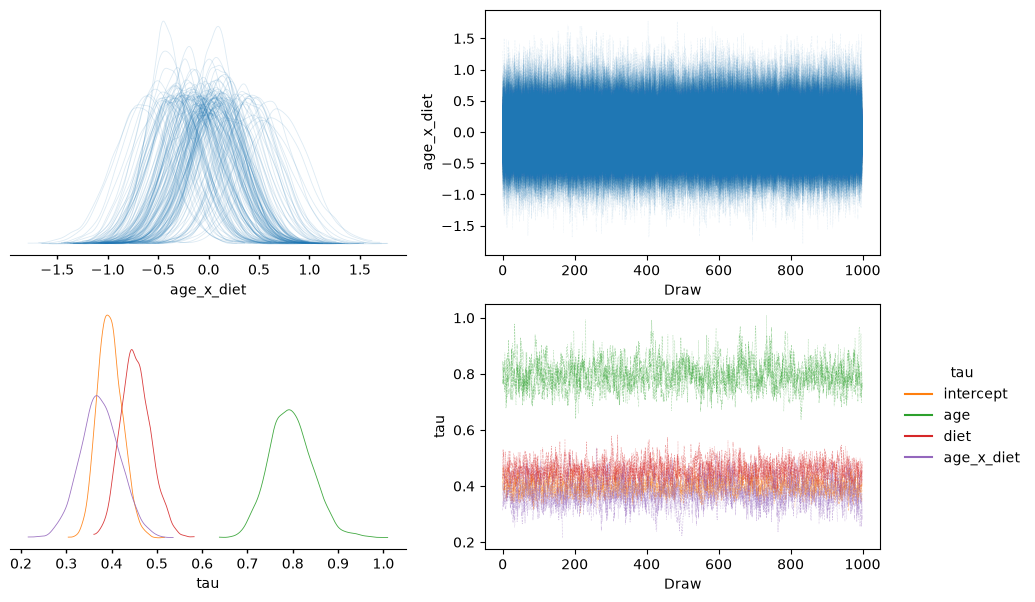

In [15]:
import arviz as az
import matplotlib.pyplot as plt
import xarray as xr

idata = az.from_numpyro(
    mcmc,
    coords={"phenotype": phenos["phenotype"].to_numpy(), "coef": COEFS},
    dims={
        "beta": ["phenotype", "coef"],
        "z": ["phenotype", "coef"],
        "sigma": ["phenotype"],
        "mu": ["coef"],
        "tau": ["coef"],
    },
)

# Keep only the interaction column of beta, plus all four global scales.
post = idata.posterior.to_dataset()
sub = xr.DataTree.from_dict({
    "posterior": xr.Dataset({
        "age_x_diet": post["beta"].sel(coef="age_x_diet", drop=True),
        "tau": post["tau"],
    }),
    "sample_stats": idata.sample_stats.to_dataset(),
})
pc = az.plot_trace_dist(
    sub,
    compact=True,
    combined=True,
    visuals={
        "dist": {"alpha": 0.15, "width": 0.6},
        "trace": {"alpha": 0.08, "width": 0.4},
    },
    aes={"color": ["coef"], "overlay": ["phenotype"]},
    aes_by_visuals={
        "dist": ["color", "overlay"],
        "trace": ["color", "overlay", "linestyle"],
    },
    figure_kwargs={"figsize": (12, 7)},
)

# visuals apply to every variable, so restore full opacity on the four tau curves and label them.
colors = pc.aes["color"].to_dataset()["mapping"].to_series()
fig = plt.gcf()
for ax in fig.axes:
    if "tau" in (ax.get_xlabel(), ax.get_ylabel()):
        for line in ax.lines:
            line.set_alpha(0.9 if ax.get_xlabel() == "tau" else 0.4)
fig.legend(
    handles=[plt.Line2D([], [], color=c, label=k) for k, c in colors.items()],
    title="tau",
    loc="center left",
    bbox_to_anchor=(0.86, 0.3),
    frameon=False,
)
fig.subplots_adjust(right=0.85)


## Prior sensitivity

The hierarchical model handles multiplicity through the shared scales $\tau_k$: every phenotype's interaction is shrunk toward the population mean by an amount learned from all 157 phenotypes. Fitting it as a full Bayesian model, rather than plugging in OLS estimates and standard errors, carries the uncertainty in each phenotype's residual SD $\sigma_i$ and in the population parameters through to every phenotype's posterior. The cost is that the result depends on the prior, so this section measures how much.

There are two kinds of prior choice, which we expect to matter to different degrees:

- **The hyperprior on the scales $\tau_k$** (HalfNormal, wider HalfNormal, inverse gamma on $\tau_k^2$). With 157 phenotypes the data should pin down each $\tau_k$, so we expect little change.
- **The population distribution of the coefficients** (normal, Student-t, regularized horseshoe). This sets how much prior mass sits at or near zero and how heavy the tails are, which governs whether a moderate interaction is shrunk to zero or left alone. We expect this to matter more.

All variants share the likelihood and the per-phenotype residual SDs. The families are:

| Family                | Population distribution                                                                                                                                                                        | Applied to                                                                                                                     |
| --------------------- | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------ |
| Normal                | $\beta_{ki} = \mu_k + \tau_k z_{ki}$, $z_{ki} \sim N(0, 1)$                                                                                                                                    | All four coefficient types. The model above.                                                                                   |
| Student-t             | $\beta_{ki} = \mu_k + \tau_k z_{ki}$, $z_{ki} \sim t_{\nu_k}(0, 1)$, $\nu_k \sim \text{Gamma}(2, 0.1)$                                                                                         | All four coefficient types. One degrees-of-freedom parameter per type, learned from the data. Small $\nu_k$ means heavy tails. |
| Regularized horseshoe | $\gamma_i = \tau_3 \tilde\lambda_i z_{3i}$, $\lambda_i \sim \text{HalfCauchy}(1)$, $\tilde\lambda_i^2 = \dfrac{c^2 \lambda_i^2}{c^2 + \tau_3^2 \lambda_i^2}$, $c^2 \sim \text{InvGamma}(2, 2)$ | The interaction only. The other three coefficient types stay normal.                                                           |

The regularized horseshoe (Piironen and Vehtari, 2017) encodes the belief that most interactions are close to zero and the rest are moderate. Each phenotype has its own local scale $\lambda_i$. The half-Cauchy prior on $\lambda_i$ puts a lot of mass near zero, so most interactions are shrunk hard toward zero, while a few can have large local scales and escape the shrinkage. In the plain horseshoe, those escaping interactions are left almost unshrunk, which amounts to a prior belief that some interactions are very large. The regularization caps this: when $\tau_3 \lambda_i$ is large compared with the slab scale $c$, $\tau_3 \tilde\lambda_i \approx c$, so the nonzero interactions behave like draws from a $N(0, c^2)$ slab. The prior $c^2 \sim \text{InvGamma}(2, 2)$ corresponds to a Student-t slab with 4 degrees of freedom and scale 1, so interactions much larger than about one phenotype SD are not expected. The global scale $\tau_3$ controls how many interactions escape the shrinkage overall.

The horseshoe does not assign interactions to "zero" and "nonzero" groups, but it has a continuous analog of an inclusion probability. For a phenotype whose interaction estimate has standard error $s_i$, the posterior mean of $\gamma_i$ is approximately $(1 - \kappa_i)$ times the estimate, where

$$\kappa_i = \frac{1}{1 + \tau_3^2 \tilde\lambda_i^2 / s_i^2}$$

is the shrinkage factor: $\kappa_i \approx 1$ means the interaction is shrunk to zero, and $\kappa_i \approx 0$ means it is left as estimated (Carvalho, Polson and Scott, 2010). In the 2×2 design $s_i = \sigma_i \sqrt{\sum_{c} 1/n_{ic}}$, where $n_{ic}$ are the cell sizes, so $\kappa_i$ is recorded for every posterior draw as the deterministic site `one_minus_kappa`. We report the posterior mean of $1 - \kappa_i$, classify an interaction as nonzero when it exceeds 0.5, and report the sum $m_\text{eff} = \sum_i (1 - \kappa_i)$, which estimates the number of nonzero interactions. For comparison with the other families, we also report whether the 95% interval for $\gamma_i$ excludes zero.


In [16]:
from functools import partial

from numpyro.diagnostics import summary
from numpyro.handlers import condition


def inv_gamma_on_square(a, b):
    """Distribution of tau when tau^2 ~ InverseGamma(a, b)."""
    return dist.TransformedDistribution(
        dist.InverseGamma(a, b), dist.transforms.PowerTransform(0.5)
    )


def hier_model(
    age, trt, pheno, n_pheno, y=None, family="normal", tau_prior=None, prior_scale=1.0
):
    tau_prior = dist.HalfNormal(prior_scale) if tau_prior is None else tau_prior

    with numpyro.plate("coef", 4):
        mu = numpyro.sample("mu", dist.Normal(0, prior_scale))
        tau = numpyro.sample("tau", tau_prior)
        if family == "student_t":
            nu = numpyro.sample("nu", dist.Gamma(2, 0.1))

        with numpyro.plate("phenotype", n_pheno):
            if family == "student_t":
                z = numpyro.sample("z", dist.StudentT(nu, 0, 1))
            else:
                z = numpyro.sample("z", dist.Normal(0, 1))

    beta = mu + tau * z  # n_pheno x 4

    with numpyro.plate("phenotype", n_pheno):
        sigma = numpyro.sample("sigma", dist.HalfNormal(prior_scale))

    if family == "reg_horseshoe":
        # The interaction gets a regularized horseshoe prior centered at zero: tau[3] is the
        # global scale and z[:, 3] is reused as the standard normal draw. mu[3] is unused.
        c2 = numpyro.sample("c2", dist.InverseGamma(2, 2))  # squared slab scale
        with numpyro.plate("phenotype", n_pheno):
            lam = numpyro.sample("lam", dist.HalfCauchy(1))
        lam_tilde = numpyro.deterministic(
            "lam_tilde", jnp.sqrt(c2 * lam**2 / (c2 + tau[3] ** 2 * lam**2))
        )
        beta = beta.at[:, 3].set(tau[3] * lam_tilde * z[:, 3])

        # Shrinkage: 1 - kappa_i is the fraction of the interaction estimate kept. The estimate's
        # standard error in the 2x2 design is sigma_i * sqrt(sum over cells of 1 / n_cell).
        n_cell = jnp.zeros((n_pheno, 4)).at[pheno, 2 * age + trt].add(1)
        se = sigma * jnp.sqrt((1 / n_cell).sum(axis=1))
        ratio = (tau[3] * lam_tilde / se) ** 2
        numpyro.deterministic("one_minus_kappa", ratio / (1 + ratio))

    beta = numpyro.deterministic("beta", beta)
    b = beta[pheno]
    mean = b[:, 0] + b[:, 1] * age + b[:, 2] * trt + b[:, 3] * age * trt
    with numpyro.plate("obs", len(age)):
        numpyro.sample("y", dist.Normal(mean, sigma[pheno]), obs=y)

The helpers below fit one variant and summarize it. `fixed` holds parameter values to condition on instead of sampling, which is used for the empirical Bayes variants further down.


In [17]:
jdata = {k: jnp.asarray(v) if isinstance(v, np.ndarray) else v for k, v in data.items()}
DIMS = {
    "mu": ["coef"],
    "tau": ["coef"],
    "nu": ["coef"],
    "z": ["phenotype", "coef"],
    "lam": ["phenotype"],
    "lam_tilde": ["phenotype"],
    "one_minus_kappa": ["phenotype"],
    "beta": ["phenotype", "coef"],
    "sigma": ["phenotype"],
}


def fit(fixed=None, seed=28291, **model_kwargs):
    model = partial(hier_model, **model_kwargs)
    if fixed:
        model = condition(model, {k: jnp.asarray(v) for k, v in fixed.items()})
    # The horseshoe's funnel-shaped posterior needs smaller steps.
    target = 0.99 if model_kwargs.get("family") == "reg_horseshoe" else 0.9
    mcmc = MCMC(
        NUTS(model, target_accept_prob=target),
        num_warmup=1000,
        num_samples=1000,
        num_chains=4,
        progress_bar=True,
    )
    mcmc.run(jax.random.PRNGKey(seed), **jdata)
    return mcmc


def to_trace(mcmc, fixed=None):
    # az.from_numpyro re-runs the model with draws from the prior to find its structure, and a
    # draw from InvGamma(0.001, 0.001) can overflow to inf. Building the trace from the
    # posterior samples avoids that. Fixed (conditioned) parameters are added back as constants.
    samples = {
        k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()
    }
    n_chain, n_draw = next(iter(samples.values())).shape[:2]
    for k, v in (fixed or {}).items():
        samples[k] = np.broadcast_to(np.asarray(v), (n_chain, n_draw) + np.shape(v))
    diverging = np.asarray(mcmc.get_extra_fields(group_by_chain=True)["diverging"])
    return az.from_dict(
        {"posterior": samples, "sample_stats": {"diverging": diverging}},
        coords={"phenotype": phenos["phenotype"].to_numpy(), "coef": COEFS},
        dims={k: v for k, v in DIMS.items() if k in samples},
    )


def flag_interactions(trace):
    """Per-phenotype posterior summary of the interaction, flagged when the 95% interval excludes zero."""
    b3 = trace.posterior["beta"].sel(coef="age_x_diet")
    q = b3.quantile([0.025, 0.975], dim=["chain", "draw"])
    out = pd.DataFrame({
        "post_mean": b3.mean(["chain", "draw"]).to_series(),
        "lcb": q.sel(quantile=0.025, drop=True).to_series(),
        "ucb": q.sel(quantile=0.975, drop=True).to_series(),
    })
    out["flagged"] = (out["lcb"] > 0) | (out["ucb"] < 0)
    if "one_minus_kappa" in trace.posterior:
        out["1-kappa"] = (
            trace.posterior["one_minus_kappa"].mean(["chain", "draw"]).to_series()
        )
    return out


def describe_fit(mcmc, trace):
    diag = summary(mcmc.get_samples(group_by_chain=True))
    post = trace.posterior.to_dataset()
    flags = flag_interactions(trace)
    row = {
        "CI excludes 0": int(flags["flagged"].sum()),
        "1-kappa > 0.5": int((flags["1-kappa"] > 0.5).sum())
        if "1-kappa" in flags
        else None,
        "divergences": int(mcmc.get_extra_fields()["diverging"].sum()),
        "max r_hat": max(float(np.nanmax(d["r_hat"])) for d in diag.values()),
    }
    stats = {"tau (interaction)": post["tau"].sel(coef="age_x_diet")}
    if "nu" in post:
        stats["nu (interaction)"] = post["nu"].sel(coef="age_x_diet")
    if "c2" in post:
        stats["slab scale c"] = np.sqrt(post["c2"])
        stats["m_eff"] = post["one_minus_kappa"].sum("phenotype")
    for label, x in stats.items():
        lo, med, hi = x.quantile([0.025, 0.5, 0.975]).values
        row[label] = (
            f"{med:.2f}" if np.isclose(lo, hi) else f"{med:.2f} [{lo:.2f}, {hi:.2f}]"
        )
    return row

### Variants

1. **Normal, wider priors.** The base model with every prior scale multiplied by 10: $\mu_k \sim N(0, 10)$, $\tau_k \sim \text{HalfNormal}(10)$, $\sigma_i \sim \text{HalfNormal}(10)$. If the data dominate the hyperpriors, this should flag the same phenotypes as the base model.
2. **Student-t and regularized horseshoe** populations, with the base hyperpriors. For the horseshoe the hyperprior applies to the global scale $\tau_3$.
3. **Inverse gamma on $\tau_k^2$** for the normal and Student-t families. The common "vague" choice $\tau_k^2 \sim \text{InvGamma}(0.001, 0.001)$ is known to be informative when the true $\tau_k$ is near zero (Gelman, 2006), which makes it a useful stress test. We omit it for the regularized horseshoe because the sampler did not converge: with this prior on the global scale there were divergent transitions, $\hat{R}$ above 1.05, and draws of $\tau_3$ in the millions. The prior has a very heavy right tail, and the horseshoe's global scale is only weakly identified because it trades off against the local scales $\lambda_i$.

For the inverse gamma, choosing the parameters $(a, b)$ that "fit best", by maximizing the marginal likelihood of the data, does not give a usable prior here. Each $\tau_k$ is well identified, so the marginal likelihood is highest when the prior concentrates all its mass at the best-fitting value of $\tau_k$, with $a, b \to \infty$. The best-fitting hyperprior is therefore a point mass, and the model becomes an **empirical Bayes** model: the population parameters are fixed at estimates and their uncertainty is dropped. We fit that limit directly as a fourth variant for each family, fixing $\mu_k$, $\tau_k$ (and $\nu_k$ for the Student-t, the slab scale $c^2$ for the horseshoe) at their posterior medians from the full model. Comparing it with the full model shows how much the posterior uncertainty in the population parameters matters.


In [18]:
VARIANTS = {
    "normal, HalfNormal(1)": dict(family="normal"),
    "normal, HalfNormal(10), all priors x10": dict(family="normal", prior_scale=10.0),
    "normal, tau^2 ~ InvGamma(0.001, 0.001)": dict(
        family="normal", tau_prior=inv_gamma_on_square(0.001, 0.001)
    ),
    "student_t, HalfNormal(1)": dict(family="student_t"),
    "student_t, tau^2 ~ InvGamma(0.001, 0.001)": dict(
        family="student_t", tau_prior=inv_gamma_on_square(0.001, 0.001)
    ),
    "reg_horseshoe, HalfNormal(1)": dict(family="reg_horseshoe"),
}

fits, traces = {}, {}
for name, kwargs in VARIANTS.items():
    print(f"Fitting {name}...")
    fits[name] = fit(**kwargs)
    traces[name] = to_trace(fits[name])

# Empirical Bayes: fix the population parameters at their posterior medians from the HalfNormal(1) fit.
for family in ["normal", "student_t", "reg_horseshoe"]:
    post = traces[f"{family}, HalfNormal(1)"].posterior.to_dataset()
    fixed = {
        k: post[k].median(["chain", "draw"]).values
        for k in ["mu", "tau", "nu", "c2"]
        if k in post
    }
    name = f"{family}, empirical Bayes (fixed at medians)"
    fits[name] = fit(fixed=fixed, family=family)
    traces[name] = to_trace(fits[name], fixed=fixed)

Fitting normal, HalfNormal(1)...


  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

...

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

The table summarizes each variant: the number of phenotypes flagged under each decision rule, sampler diagnostics, and the posterior for the interaction's scale $\tau_3$ (the global scale, for the horseshoe), the degrees of freedom $\nu_3$ for the Student-t, and the slab scale $c$ and effective number of nonzero interactions $m_\text{eff}$ for the horseshoe. For the empirical Bayes variants the population parameters are fixed, so they have no interval. Note that $\tau_3$ is not comparable across families: in the horseshoe it multiplies the local scales $\tilde\lambda_i$.


In [20]:
results = pd.DataFrame({
    name: describe_fit(fits[name], traces[name]) for name in fits
}).T
results

,CI excludes 0,1-kappa > 0.5,divergences,max r_hat,tau (interaction),nu (interaction),slab scale c,m_eff
"normal, HalfNormal(1)",9,None,0,1.001637,"0.38 [0.29, 0.46]",NaN,NaN,NaN
"normal, HalfNormal(10), all priors x10",9,None,0,1.001643,"0.37 [0.29, 0.47]",NaN,NaN,NaN
"normal, tau^2 ~ InvGamma(0.001, 0.001)",8,None,0,1.001671,"0.37 [0.29, 0.46]",NaN,NaN,NaN
"student_t, HalfNormal(1)",11,None,0,1.002283,"0.35 [0.26, 0.45]","17.74 [3.96, 55.47]",NaN,NaN
"student_t, tau^2 ~ InvGamma(0.001, 0.001)",10,None,0,1.002205,"0.35 [0.25, 0.44]","17.14 [3.78, 56.06]",NaN,NaN
"reg_horseshoe, HalfNormal(1)",6,15,0,1.009591,"0.37 [0.15, 1.19]",NaN,"0.70 [0.48, 1.17]","56.83 [37.02, 75.22]"
"normal, empirical Bayes (fixed at medians)",11,None,0,1.003034,0.38,NaN,NaN,NaN
"student_t, empirical Bayes (fixed at medians)",11,None,0,1.003327,0.35,17.74,NaN,NaN
"reg_horseshoe, empirical Bayes (fixed at medians)",5,16,0,1.003127,0.37,NaN,0.70,"57.12 [51.23, 62.85]"


Which phenotypes are flagged by a 95% interval excluding zero under each variant, for every phenotype flagged at least once. The `1-kappa` column is the posterior mean of $1 - \kappa_i$ from the regularized horseshoe with the HalfNormal(1) hyperprior, and the last columns repeat the frequentist results for comparison.


In [21]:
flags = pd.DataFrame({
    name: flag_interactions(tr)["flagged"] for name, tr in traces.items()
})
flags["1-kappa"] = flag_interactions(traces["reg_horseshoe, HalfNormal(1)"])["1-kappa"]
flags = flags.join(freq.set_index("phenotype")[["bonferroni", "bh05", "bh10"]])
flags = flags[flags[list(traces)].any(axis=1) | (flags["1-kappa"] > 0.5)]
flags.assign(n_variants=flags[list(traces)].sum(axis=1)).sort_values(
    "1-kappa", ascending=False
)

,"normal, HalfNormal(1)","normal, HalfNormal(10), all priors x10","normal, tau^2 ~ InvGamma(0.001, 0.001)","student_t, HalfNormal(1)","student_t, tau^2 ~ InvGamma(0.001, 0.001)","reg_horseshoe, HalfNormal(1)","normal, empirical Bayes (fixed at medians)","student_t, empirical Bayes (fixed at medians)","reg_horseshoe, empirical Bayes (fixed at medians)",1-kappa,bonferroni,bh05,bh10,n_variants
phenotype,,,,,,,,,,,,,,
Lean_mass_NMR,True,True,True,True,True,False,True,True,False,0.699809,False,False,True,7
Body_mass_NMR,False,True,False,True,True,False,True,True,False,0.640284,False,False,True,5
HDL_fasting,True,True,True,True,True,True,True,True,True,0.622725,False,False,False,9
spfrth,True,False,False,True,False,True,True,True,False,0.612633,False,False,True,5
RR,True,True,True,True,True,True,True,True,True,0.609217,False,False,True,9
conc_Insulin,True,True,True,True,True,True,True,True,True,0.595911,True,True,True,9
HR,True,True,True,True,True,True,True,True,True,0.578369,False,False,True,9
eu_transf_arousal,False,False,False,True,True,False,True,True,False,0.575254,False,True,True,4
PcPPI_PP69,False,False,False,False,False,False,False,False,False,0.565518,False,False,False,0
